##  واردکردن کتابخانه‌ها



In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42


##  خواندن دو فایل و ساخت برچسب هدف



In [14]:
def read_ansur_csv(path):
    try:
        return pd.read_csv(path, encoding="utf-8-sig")
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="cp1252")

male = read_ansur_csv(MALE_FILE)
female = read_ansur_csv(FEMALE_FILE)


# یکدست‌سازی نام ستون‌ها
male.columns = male.columns.str.strip().str.lower()
female.columns = female.columns.str.strip().str.lower()

def add_group_label(data, expected_label):
    data = data.copy()
    source_column = next(
        (col for col in ["sex", "gender"] if col in data.columns),
        None
    )

    if source_column is not None:
        observed = set(
            data[source_column].dropna().astype(str).str.strip().str.title()
        )
        if observed and observed != {expected_label}:
            raise ValueError(
                f"برچسب فایل {expected_label} است، اما در ستون {source_column} "
                f"این مقادیر دیده شد: {observed}"
            )
        data = data.drop(columns=[source_column])

    data["gender"] = expected_label
    return data

male = add_group_label(male, "Male")
female = add_group_label(female, "Female")

print("Male shape:", male.shape)
print("Female shape:", female.shape)
print("\nMale columns:", male.columns.tolist())


Male shape: (4082, 108)
Female shape: (1986, 108)

Male columns: ['subjectid', 'abdominalextensiondepthsitting', 'acromialheight', 'acromionradialelength', 'anklecircumference', 'axillaheight', 'balloffootcircumference', 'balloffootlength', 'biacromialbreadth', 'bicepscircumferenceflexed', 'bicristalbreadth', 'bideltoidbreadth', 'bimalleolarbreadth', 'bitragionchinarc', 'bitragionsubmandibulararc', 'bizygomaticbreadth', 'buttockcircumference', 'buttockdepth', 'buttockheight', 'buttockkneelength', 'buttockpopliteallength', 'calfcircumference', 'cervicaleheight', 'chestbreadth', 'chestcircumference', 'chestdepth', 'chestheight', 'crotchheight', 'crotchlengthomphalion', 'crotchlengthposterioromphalion', 'earbreadth', 'earlength', 'earprotrusion', 'elbowrestheight', 'eyeheightsitting', 'footbreadthhorizontal', 'footlength', 'forearmcenterofgriplength', 'forearmcircumferenceflexed', 'forearmforearmbreadth', 'forearmhandlength', 'functionalleglength', 'handbreadth', 'handcircumference', 'han

## بررسی اولیهٔ کیفیت داده


In [15]:
df = pd.concat([male, female], ignore_index=True)

# اطمینان از اینکه stature عددی است؛ مقدارهای غیرقابل‌تبدیل گمشده می‌شوند
df["stature"] = pd.to_numeric(df["stature"], errors="coerce")
df = df.dropna(subset=["gender", "stature"])
df = df[df["stature"] > 0]

print("Combined shape:", df.shape)
print("\nGroup counts:")
print(df["gender"].value_counts())
print("\nMissing values (columns with missing data):")
print(df.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False))

if "subjectid" in df.columns:
    duplicate_ids = df["subjectid"].duplicated().sum()
    print("\nDuplicate subject IDs:", duplicate_ids)
    df = df.drop_duplicates(subset="subjectid", keep="first")
else:
    print("\nNo subjectid column found; exact duplicate rows:", df.duplicated().sum())
    df = df.drop_duplicates()

print("\nShape after duplicate check:", df.shape)


Combined shape: (6068, 108)

Group counts:
gender
Male      4082
Female    1986
Name: count, dtype: int64

Missing values (columns with missing data):
ethnicity    4647
dtype: int64

Duplicate subject IDs: 0

Shape after duplicate check: (6068, 108)


## آمار توصیفی قد



In [16]:
height_summary = df.groupby("gender")["stature"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max"
)

print("Height is measured in millimeters (mm).")
display(height_summary.round(2))


Height is measured in millimeters (mm).


,count,mean,median,std,minimum,maximum
gender,,,,,,
Female,1986,1628.47,1626.0,64.20,1409,1829
Male,4082,1756.21,1755.0,68.55,1491,1993


## نمودار توزیع قد زنان و مردان



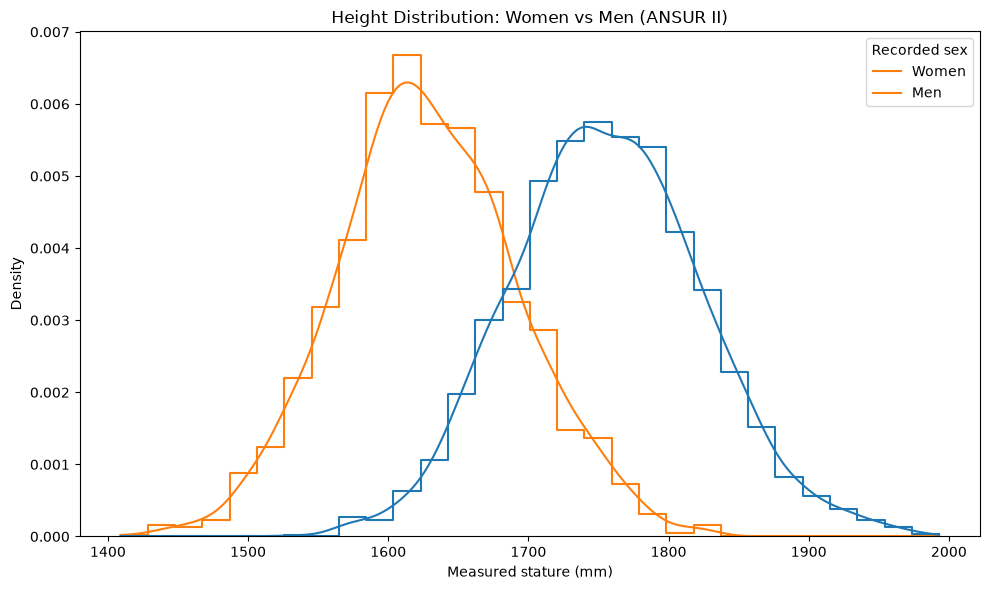

In [17]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="stature",
    hue="gender",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    kde=True
)
plt.title("Height Distribution: Women vs Men (ANSUR II)")
plt.xlabel("Measured stature (mm)")
plt.ylabel("Density")
plt.legend(title="Recorded sex", labels=["Women", "Men"])
plt.tight_layout()
plt.show()



در این نمونه، توزیع قد مردان معمولاً بالاتر و به سمت راست جابه‌جا دیده می‌شود، چون میانگین/میانهٔ `stature` در گروه مردان بیشتر است؛ این اختلاف میانگین قد در این نمونه با تفاوت‌های متوسط رشد و ابعاد بدنی بین دو گروه سازگار است، اما به معنی بلندتر بودن همهٔ مردان از همهٔ زنان نیست. «راست‌تر بودن» در صورت تمرین را بهتر است **قرارگرفتن مقادیر در سمت راست محور قد** معنی کنیم؛ این الزاماً به معنی چولگی آماری به راست نیست و چولگی را باید جداگانه با شکل توزیع یا ضریب چولگی بررسی کرد.



## تعیین ویژگی‌ها و هدف



In [18]:
y = df["gender"].copy()

columns_to_exclude = [
    "subjectid",
    "subjectnumericrace",
    "dodrace",
    "age",
    "heightin",
    "weightlbs",
    "gender",
    "sex"
]

X = df.select_dtypes(include="number").drop(
    columns=columns_to_exclude,
    errors="ignore"
).copy()

print("Samples:", len(df))
print("Features:", X.shape[1])
print("Target classes:", sorted(y.unique()))
print("\nFeature names:")
print(X.columns.tolist())


Samples: 6068
Features: 93
Target classes: ['Female', 'Male']

Feature names:
['abdominalextensiondepthsitting', 'acromialheight', 'acromionradialelength', 'anklecircumference', 'axillaheight', 'balloffootcircumference', 'balloffootlength', 'biacromialbreadth', 'bicepscircumferenceflexed', 'bicristalbreadth', 'bideltoidbreadth', 'bimalleolarbreadth', 'bitragionchinarc', 'bitragionsubmandibulararc', 'bizygomaticbreadth', 'buttockcircumference', 'buttockdepth', 'buttockheight', 'buttockkneelength', 'buttockpopliteallength', 'calfcircumference', 'cervicaleheight', 'chestbreadth', 'chestcircumference', 'chestdepth', 'chestheight', 'crotchheight', 'crotchlengthomphalion', 'crotchlengthposterioromphalion', 'earbreadth', 'earlength', 'earprotrusion', 'elbowrestheight', 'eyeheightsitting', 'footbreadthhorizontal', 'footlength', 'forearmcenterofgriplength', 'forearmcircumferenceflexed', 'forearmforearmbreadth', 'forearmhandlength', 'functionalleglength', 'handbreadth', 'handcircumference', 'han

## تقسیم train/test



In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training rows: 4854
Testing rows: 1214

Training class proportions:
gender
Male      0.673
Female    0.327
Name: proportion, dtype: float64

Testing class proportions:
gender
Male      0.673
Female    0.327
Name: proportion, dtype: float64


##  آموزش و مقایسهٔ درخت تصمیم Bagging



In [20]:
tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=100,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bagging_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", bagging_model)
])

tree_pipeline.fit(X_train, y_train)
bagging_pipeline.fit(X_train, y_train)

pred_tree_train = tree_pipeline.predict(X_train)
pred_tree_test = tree_pipeline.predict(X_test)
pred_bag_train = bagging_pipeline.predict(X_train)
pred_bag_test = bagging_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Bagging + Decision Tree"],
    "Training accuracy": [
        accuracy_score(y_train, pred_tree_train),
        accuracy_score(y_train, pred_bag_train)
    ],
    "Test accuracy": [
        accuracy_score(y_test, pred_tree_test),
        accuracy_score(y_test, pred_bag_test)
    ]
})

display(comparison.round(4))


,Model,Training accuracy,Test accuracy
0,Decision Tree,1.0,0.9786
1,Bagging + Decision Tree,1.0,0.9876


##  ارزیابی مدل Bagging روی test و ماتریس درهم‌ریختگی



Bagging test accuracy: 0.9876
Confusion matrix (rows=true, columns=predicted):
[[385  12]
 [  3 814]]


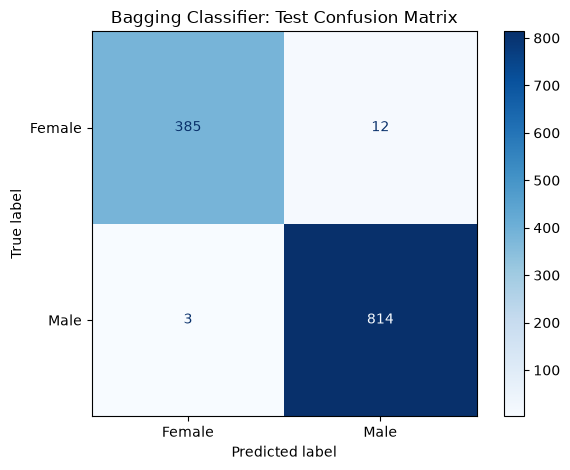

In [21]:
test_accuracy = accuracy_score(y_test, pred_bag_test)
print(f"Bagging test accuracy: {test_accuracy:.4f}")

labels = ["Female", "Male"]
cm = confusion_matrix(y_test, pred_bag_test, labels=labels)
print("Confusion matrix (rows=true, columns=predicted):")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")
plt.title("Bagging Classifier: Test Confusion Matrix")
plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">

در این تحلیل از دو فایل عمومی ANSUR II استفاده شد. پس از ادغام فایل‌ها و حذف ردیف‌های فاقد برچسب یا قد معتبر، **۶٬۰۶۸ نمونه** باقی ماند: **۴٬۰۸۲ مرد** و **۱٬۹۸۶ زن**. ستون `stature` به‌عنوان قد اندازه‌گیری‌شده و برحسب میلی‌متر استفاده شد. شناسهٔ تکراری پیدا نشد. تنها ستون دارای دادهٔ گمشده `ethnicity` بود؛ چون در این مدل از ویژگی‌های عددی استفاده شد و مقدارهای گمشدهٔ ویژگی‌ها با میانه در Pipeline جایگزین شدند، این ستون دسته‌ای در مدل استفاده نشد.


## مقایسهٔ توزیع قد

| گروه ثبت‌شده | تعداد | میانگین قد (میلی‌متر) | میانه (میلی‌متر) | انحراف معیار (میلی‌متر) | کمینه | بیشینه |
|---|---:|---:|---:|---:|---:|---:|
| زنان | 1,986 | 1,628.47 | 1,626 | 64.20 | 1,409 | 1,829 |
| مردان | 4,082 | 1,756.21 | 1,755 | 68.55 | 1,491 | 1,993 |

میانگین قد مردان در این نمونه **۱۲۷٫۷۴ میلی‌متر** بیشتر از میانگین قد زنان است؛ میانه نیز در گروه مردان **۱۲۹ میلی‌متر** بیشتر است. بنابراین توزیع قد مردان در نمودار به سمت مقادیر بزرگ‌تر جابه‌جا شده و به همین معنا «راست‌تر» دیده می‌شود. این عبارت به‌تنهایی به معنی چولگی آماری به راست نیست؛ چولگی، یعنی نامتقارن بودن شکل هر توزیع، مفهوم جداگانه‌ای است. این اختلاف دربارهٔ میانگین‌های دو گروه است و به این معنا نیست که قد هر مرد از قد هر زن بیشتر است.

## تقسیم داده و مدل‌ها

داده‌ها با نسبت **۸۰٪ آموزش و ۲۰٪ آزمون** تقسیم شدند؛ `random_state=42` برای بازتولیدپذیری ثابت بود و `stratify=y` نسبت کلاس‌ها را حفظ کرد. مجموعهٔ آموزش شامل **۴٬۸۵۴** ردیف و مجموعهٔ آزمون شامل **۱٬۲۱۴** ردیف بود. مدل‌ها با **۹۳ ویژگی عددی اندازه‌گیری‌های بدنی** آموزش دیدند. جایگزینی داده‌های گمشده با میانه درون Pipeline انجام شد تا مقدارهای آموخته‌شده فقط از داده‌های آموزش به دست بیایند.

| مدل | دقت آموزش | دقت آزمون |
|---|---:|---:|
| Decision Tree | 100.00٪ | 97.86٪ |
| Bagging + Decision Tree | 100.00٪ | 98.76٪ |

Bagging دقت آزمون را از **۹۷٫۸۶٪** به **۹۸٫۷۶٪** رساند؛ بهبود برابر با **۰٫۹۰ واحد درصد** است. هر دو مدل دقت آموزش ۱۰۰٪ دارند، در حالی که دقت آزمون پایین‌تر است؛ این فاصله نشان می‌دهد درخت‌ها دادهٔ آموزش را کاملاً یاد گرفته‌اند ויש نشانه‌ای از بیش‌برازش. در این تقسیم‌بندی خاص، Bagging آزمون را بهتر پیش‌بینی کرد، اما این بهبود کوچک به‌تنهایی تضمین نمی‌کند که در داده‌های جدید نیز همیشه بهتر عمل کند.

## ارزیابی نهایی مدل Bagging

دقت نهایی Bagging روی دادهٔ آزمون **۰٫۹۸۷۶، معادل ۹۸٫۷۶٪** بود. ماتریس درهم‌ریختگی زیر با ترتیب برچسب‌های **Female سپس Male** محاسبه شده است؛ سطرها کلاس واقعی و ستون‌ها کلاس پیش‌بینی‌شده‌اند.

| کلاس واقعی \ پیش‌بینی | Female | Male |
|---|---:|---:|
| Female | 385 | 12 |
| Male | 3 | 814 |

مدل از **۱٬۲۱۴** نمونهٔ آزمون، **۱٬۱۹۹** نمونه را درست و **۱۵** نمونه را اشتباه طبقه‌بندی کرد. از ۳۹۷ نمونهٔ واقعی Female، تعداد ۳۸۵ مورد درست و ۱۲ مورد به‌اشتباه Male پیش‌بینی شدند. از ۸۱۷ نمونهٔ واقعی Male، تعداد ۸۱۴ مورد درست و ۳ مورد به‌اشتباه Female پیش‌بینی شدند.

## پاسخ  تمرین

1. در نمودار، توزیع قد مردان بالاتر است، چون میانگین و میانهٔ قد آن‌ها در این نمونه بیشتر است. این اختلاف متوسط با تفاوت‌های بدنی میان دو گروه سازگار است، اما دربارهٔ تک‌تک افراد حکم نمی‌دهد.
2. توزیع مردان به سمت راست نمودار جابه‌جا شده است؛ یعنی مقادیر قد بالاتری را نشان می‌دهد. «راست‌تر» را نباید بدون بررسی شکل توزیع، معادل چولگی آماری به راست دانست.
3. مدل Bagging با `DecisionTreeClassifier` به‌عنوان تخمین‌گر پایه ساخته شد و از `RandomForestClassifier` استفاده نشد. دقت آزمون آن **۹۸٫۷۶٪** و ماتریس درهم‌ریختگی آن `[[385, 12], [3, 814]]` بود.
4. در مقایسه با درخت تصمیم تنها، Bagging دقت آزمون را **۰٫۹۰ واحد درصد** افزایش داد. هر دو مدل دقت آموزش ۱۰۰٪ داشتند، بنابراین در تفسیر نتیجه باید به احتمال بیش‌برازش توجه کرد.

</div>
